# Ảnh đa cấp xám dưới dạng mảng số

Tạo ảnh đa cấp xám 20x20, đọc lại ảnh và in giá trị điểm ảnh dưới dạng mảng hai chiều (2D) và mảng một chiều (1D). Mảng 1D chính là **vector đặc trưng** của ảnh khi đưa vào mô hình học máy.

In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

height, width = 20, 20                 # chiều cao, chiều rộng ảnh (số điểm ảnh)
file_name = 'grayscale_20x20.png'      # tên file ảnh sẽ lưu

## 1. Tạo ảnh đa cấp xám

Nền là dải chuyển màu ngang từ đen (0) sang trắng (255), thêm một hình vuông xám (128) ở giữa và một đường chéo trắng (255).

In [2]:
# Mỗi hàng là dải giá trị tăng đều từ 0 đến 255
image = np.tile(np.linspace(0, 255, width), (height, 1)).astype(np.uint8)
image[6:14, 6:14] = 128                # hình vuông xám ở giữa
for i in range(height):
    image[i, i] = 255                  # đường chéo trắng

Image.fromarray(image, mode='L').save(file_name)
print(f'Đã lưu ảnh: {file_name}')

Đã lưu ảnh: grayscale_20x20.png


## 2. Đọc ảnh

In [3]:
img = Image.open(file_name).convert('L')   # "L" = ảnh xám 8 bit
pixels_2d = np.array(img)                  # ma trận điểm ảnh 20 x 20
print('Kích thước ảnh (cao x rộng):', pixels_2d.shape)

Kích thước ảnh (cao x rộng): (20, 20)


## 3. Mảng hai chiều (20 x 20)

In [4]:
for row in pixels_2d:                      # in từng hàng điểm ảnh
    print(' '.join(f'{pixel:3d}' for pixel in row))

255  13  26  40  53  67  80  93 107 120 134 147 161 174 187 201 214 228 241 255
  0 255  26  40  53  67  80  93 107 120 134 147 161 174 187 201 214 228 241 255
  0  13 255  40  53  67  80  93 107 120 134 147 161 174 187 201 214 228 241 255
  0  13  26 255  53  67  80  93 107 120 134 147 161 174 187 201 214 228 241 255
  0  13  26  40 255  67  80  93 107 120 134 147 161 174 187 201 214 228 241 255
  0  13  26  40  53 255  80  93 107 120 134 147 161 174 187 201 214 228 241 255
  0  13  26  40  53  67 255 128 128 128 128 128 128 128 187 201 214 228 241 255
  0  13  26  40  53  67 128 255 128 128 128 128 128 128 187 201 214 228 241 255
  0  13  26  40  53  67 128 128 255 128 128 128 128 128 187 201 214 228 241 255
  0  13  26  40  53  67 128 128 128 255 128 128 128 128 187 201 214 228 241 255
  0  13  26  40  53  67 128 128 128 128 255 128 128 128 187 201 214 228 241 255
  0  13  26  40  53  67 128 128 128 128 128 255 128 128 187 201 214 228 241 255
  0  13  26  40  53  67 128 128 128 128 

## 4. Mảng một chiều

`flatten()` duỗi ảnh theo từng hàng thành vector 400 phần tử.

In [5]:
pixels_1d = pixels_2d.flatten()            # vector đặc trưng của ảnh
print(f'Số phần tử: {pixels_1d.size}')
np.set_printoptions(threshold=np.inf, linewidth=120)
print(pixels_1d)

Số phần tử: 400
[255  13  26  40  53  67  80  93 107 120 134 147 161 174 187 201 214 228 241 255   0 255  26  40  53  67  80  93 107
 120 134 147 161 174 187 201 214 228 241 255   0  13 255  40  53  67  80  93 107 120 134 147 161 174 187 201 214 228
 241 255   0  13  26 255  53  67  80  93 107 120 134 147 161 174 187 201 214 228 241 255   0  13  26  40 255  67  80
  93 107 120 134 147 161 174 187 201 214 228 241 255   0  13  26  40  53 255  80  93 107 120 134 147 161 174 187 201
 214 228 241 255   0  13  26  40  53  67 255 128 128 128 128 128 128 128 187 201 214 228 241 255   0  13  26  40  53
  67 128 255 128 128 128 128 128 128 187 201 214 228 241 255   0  13  26  40  53  67 128 128 255 128 128 128 128 128
 187 201 214 228 241 255   0  13  26  40  53  67 128 128 128 255 128 128 128 128 187 201 214 228 241 255   0  13  26
  40  53  67 128 128 128 128 255 128 128 128 187 201 214 228 241 255   0  13  26  40  53  67 128 128 128 128 128 255
 128 128 187 201 214 228 241 255   0  13  26  40

## 5. Hiển thị ảnh kèm giá trị điểm ảnh

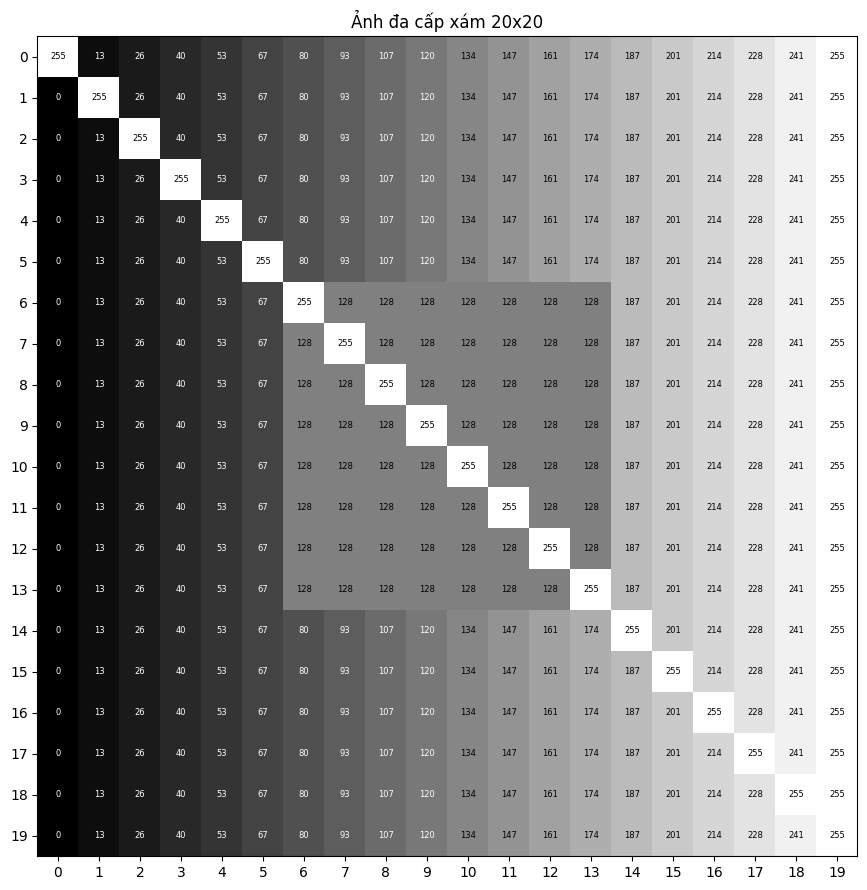

In [6]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(pixels_2d, cmap='gray', vmin=0, vmax=255)
for r in range(height):                    # r: chỉ số hàng
    for c in range(width):                 # c: chỉ số cột
        value = pixels_2d[r, c]
        # chữ đen trên nền sáng, chữ trắng trên nền tối
        ax.text(c, r, str(value), ha='center', va='center', fontsize=6,
                color='black' if value > 127 else 'white')
ax.set_title('Ảnh đa cấp xám 20x20')
ax.set_xticks(range(width))
ax.set_yticks(range(height))
plt.tight_layout()
plt.show()